
# Extended-phase-space integrators on true dynamics
Explicit (Pihajoki, Tao) and semi-explicit (Jayawardana-Ohsawa) methods on nine Hamiltonian systems.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Could not find the project root containing the src folder.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\USER\Desktop\hamiltonian-dynamics-benchmark


In [2]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from src.datasets.generate import generate_dataset
from src.datasets.systems.low_dim import (
    SimplePendulum, DoublePendulum, MassSpringSystem, HenonHeiles, FermiPastaUlamTsingou,
    SphericalPendulum, KeplerProblem, ChargedParticleMagneticTrap,
)

from src.datasets.systems.low_dim.presets import sun_earth_jupiter_em

from src.datasets.systems.low_dim import CoupledOscillators
from src.datasets.integrators import midpoint, verlet
from src.integrators.explicit_extended_space import tao, pihajoki, tao_step, pihajoki_step
from src.integrators.semiexplicit_extended_space import semiexplicit, _compose, _strang, to_qpxy

warnings.filterwarnings("ignore")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "legend.fontsize": 8}
)

pd.set_option("display.float_format", "{:.3g}".format)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## Configuration

In [3]:
SYSTEM_BUILDERS = {
    "simple_pendulum": lambda: SimplePendulum(),
    "double_pendulum": lambda: DoublePendulum(),
    "mass_spring": lambda: MassSpringSystem(),
    "henon_heiles": lambda: HenonHeiles(),
    "coupled_oscillators": lambda: CoupledOscillators(n=3),
    "fput": lambda: FermiPastaUlamTsingou(m=3, omega=50.0),
    "kepler":             lambda: KeplerProblem(dim=2),
    "charged_particle":   lambda: ChargedParticleMagneticTrap(dim=2),
    "spherical_pendulum": lambda: SphericalPendulum(),
}
SYSTEMS = list(SYSTEM_BUILDERS)  

# systems shown in the main text; all others go to the annex
MAIN_SYSTEMS = ["double_pendulum", "henon_heiles", "kepler", "spherical_pendulum", "fput"]

_DEFAULT = dict(
    T=50.0, steps=1000, T_err=50.0, conv_T=10.0,
    roll_T=15.0, roll_steps=300,
    separable=True, chaotic=False, omega0=1.0, reversible=True,
)

SYSTEM_CFG = {k: dict(_DEFAULT) for k in SYSTEM_BUILDERS}
SYSTEM_CFG["double_pendulum"].update(
    T=20.0, steps=2000, T_err=5.0, conv_T=5.0,
    roll_T=5.0, roll_steps=250, separable=False, chaotic=True,
)

SYSTEM_CFG["henon_heiles"].update(
    T_err=20.0, conv_T=5.0, chaotic=True,
)

SYSTEM_CFG["fput"] = dict(_DEFAULT)
SYSTEM_CFG["fput"].update(T=10.0, steps=2000, T_err=10.0, conv_T=1.0,
                          separable=True, chaotic=False, omega0=5.0)

SYSTEM_CFG["kepler"].update(T=50.0, steps=1000, T_err=50.0, conv_T=10.0,
                            separable=True, omega0=2.0)

SYSTEM_CFG["charged_particle"].update(T=30.0, steps=1500, T_err=30.0, conv_T=5.0,
                                      separable=False, omega0=2.0, reversible=False)

SYSTEM_CFG["spherical_pendulum"].update(T=30.0, steps=1500, T_err=30.0, conv_T=5.0,
                                        separable=False, omega0=1.0, roll_steps=600)

# ----------------------------------------------------------------------------
# True Dynamics part settings
# ----------------------------------------------------------------------------
N_TEST, SEED_TEST = 8, 123                  # test trajectories per system (metrics: median over them)
CONV_STEPS = [5, 10, 20, 40, 80, 160, 320]  # step counts of the convergence / stability sweep (h = conv_T / n)
STAB_TOL = 0.5                              # "stable" = max drift < STAB_TOL * (1 + |H0|)
TAO_OMEGA_REL = 10.0                        # Tao omega used in the main comparison (x omega0)
OMEGAS_REL = [0.0, 1.0, 10.0, 100.0]        # Tao restraint sweep (x omega0)
FOCUS_SYSTEM = "double_pendulum"                 
POINCARE_T, POINCARE_STEPS, POINCARE_N = 400.0, 8000, 4

# ----------------------------------------------------------------------------
# Extended-space diagnostics settings
# ----------------------------------------------------------------------------
JO_KW = dict(composition="triple_jump", tol=1e-12, max_iter=100, solver="newton")
JO_TOLS = [1e-6, 1e-9, 1e-12, 1e-14]    # projection tolerance sweep (A6)
EXT_STRIDE_MAX = 400                    # max number of time samples for the extended H / momentum evaluations
SYMP_STATES = dict(n_traj=3, time_fracs=(0.0, 0.5, 1.0))   # states at which the extended symplectic defect is measured
COST_TARGET = 1e-3                      # error level used for the "cost to reach target accuracy" metric
INV_TOL = 1e-6                          # a candidate momentum counts as conserved if the reference solve keeps it this well

# ----------------------------------------------------------------------------
# Output
# ----------------------------------------------------------------------------
OUT = ROOT / "outputs" / "extended_phase_space"
OUT.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Methods: label -> (solver name, omega)
# ----------------------------------------------------------------------------
def methods_for(key, verlet=True):
    cfg = SYSTEM_CFG[key]
    m = {
        "Pihajoki": ("pihajoki", None),                 # mixing (alpha, beta) = (1, 0)
        "Pihajoki (0,0)": ("pihajoki00", None),         # symmetric mixing: symplectic in the extended space
        "Tao (order 2)": ("tao", TAO_OMEGA_REL * cfg["omega0"]),
        "Tao (order 4)": ("tao4", TAO_OMEGA_REL * cfg["omega0"]),
        "J-O (order 2)": ("jayawardana_ohsawa", None),
        "J-O (order 4)": ("jayawardana_ohsawa4", None),
        "Midpoint": ("midpoint", None),
        "RK4": ("rk4", None),
    }
    if verlet and cfg["separable"]:
        m["Verlet"] = ("verlet", None)
    return m


ALL_LABELS = list(dict.fromkeys(l for k in SYSTEMS for l in methods_for(k)))
BASELINES = {"Midpoint", "RK4", "Verlet"}
COLORS = {
    "Pihajoki": "tab:orange",
    "Pihajoki (0,0)": "gold",
    "Tao (order 2)": "tab:blue",
    "Tao (order 4)": "tab:pink",
    "J-O (order 2)": "tab:cyan",
    "J-O (order 4)": "tab:brown",
    "Midpoint": "tab:green",
    "RK4": "tab:red",
    "Verlet": "tab:purple",
}

def sty(label):
    return dict(color=COLORS.get(label), ls="--" if label in BASELINES else "-", lw=1.5)

## Load shared helpers

In [4]:
HELPERS = ROOT / "notebooks" / "integrators" / "extended_phase_space" / "ext_common.py"
exec(HELPERS.read_text())   
print("shared helpers loaded from", HELPERS)

shared helpers loaded from C:\Users\USER\Desktop\hamiltonian-dynamics-benchmark\notebooks\integrators\extended_phase_space\ext_common.py


# Integrators on the true dynamics

## Benchmark

In [5]:
def benchmark_true(key, n_test=N_TEST, seed=SEED_TEST):
    cfg = SYSTEM_CFG[key]
    system = SYSTEM_BUILDERS[key]()
    d = system.state_dim // 2
    Y0 = np.asarray(system.generate_initial_conditions(n_test, seed=seed), float)
    f_flat = oracle_field_batched(system, n_test, d)
    H = true_H_fn(system)
    H0 = float(np.mean(np.abs(H(Y0))))
    methods = methods_for(key)
    T, n = cfg["T"], cfg["steps"]
    t = np.linspace(0.0, T, n + 1)
    i_err = int(round(cfg["T_err"] / T * n))

    # Long run: drift + error curves + extended-space diagnostics
    ref = solve_reference(f_flat, Y0, d, T, n, 1e-10, 1e-10)
    invs = detect_invariants(ref, d)               # momentum-like invariants conserved by the exact flow
    inv = invs[0] if invs else None
    tr_idx = list(range(min(SYMP_STATES["n_traj"], n_test)))
    ti_idx = [int(round(f * n)) for f in SYMP_STATES["time_fracs"]]
    runs = {}
    for label, r in run_all(methods, Y0, d, T, n, f_flat, system.dynamics).items():
        if r["traj"] is None:
            continue
        name, omega = methods[label]
        e = ext_diagnostics(r, name, omega, n_test, d, n, H_fn=H, inv=inv)
        idx = np.unique(np.linspace(0, n, min(n + 1, EXT_STRIDE_MAX)).round().astype(int))
        run = dict(
            err=state_error(r["traj"], ref),
            drift=energy_drift(H, r["traj"]),
            evals=r["evals"], seconds=r["seconds"], ext=e, idx=idx,
            symp_states=ext_sample_states(r["ext"], n_test, d, tr_idx, ti_idx) if e else None,
        )
        if inv is not None:
            run["mom"] = phys_invariant_drift(inv["fn"], r["traj"], idx)
        if e:
            run["err_copy2"] = state_error(e["copy2"], ref)
            run["err_mean"] = state_error(e["mean"], ref)
        runs[label] = run

    # Convergence / stability sweep (also records the energy drift and the J-O iteration counts)
    sweep = {label: [] for label in methods}
    Tc = cfg["conv_T"]
    for nn in CONV_STEPS:
        refc = solve_reference(f_flat, Y0, d, Tc, nn, 1e-10, 1e-10)
        h = Tc / nn
        for label, r in run_all(methods, Y0, d, Tc, nn, f_flat, system.dynamics).items():
            if r["traj"] is None or not np.isfinite(r["traj"]).all():
                sweep[label].append(dict(h=h, err=np.inf, evals=np.nan, seconds=r["seconds"],
                                         drift=np.inf, iters=np.nan, stable=False))
                continue
            dr = max_over_time(energy_drift(H, r["traj"]))
            st = r["ext"]["stats"] if r["ext"] else {}
            sweep[label].append(dict(
                h=h,
                err=mean_over_time(state_error(r["traj"], refc)),
                evals=r["evals"] / h,           # field evaluations per unit time
                seconds=r["seconds"],
                drift=dr,
                iters=float(np.mean(st["iterations"])) if "iterations" in st else np.nan,
                stable=bool(dr < STAB_TOL * (1.0 + H0)),
            ))

    # Summary rows (physical + extended + cost metrics)
    nan = np.nan
    rows = []
    reversible = cfg.get("reversible", True)
    for label, r in runs.items():
        name, omega = methods[label]
        e = r["ext"]
        pts = sweep[label]
        hmax = np.nan
        for p in sorted(pts, key=lambda p: p["h"]):  # largest h such that all smaller h are stable
            if p["stable"]:
                hmax = p["h"]
            else:
                break
        good = [p for p in pts if p["stable"]]
        row = dict(
            system=key, method=label, chaotic=cfg["chaotic"],
            # --- physical (returned trajectory = copy 1 for extended methods)
            err_Terr=err_at(r["err"], i_err),
            drift_max=max_over_time(r["drift"]),
            drift_slope=drift_slope(t, r["drift"]),
            order=fit_order([p["h"] for p in good], [p["err"] for p in good]),
            h_max_stable=hmax,
            phys_symp_defect=sympl_defect(system, name, omega, T / n, Y0[:3]),
            mom_name=inv["name"] if inv else None,
            mom_drift_phys=max_over_time(r["mom"]) if "mom" in r else nan,
            rev_err=(reversibility_error(name, omega, Y0, d, T / 5, max(n // 5, 2), f_flat, system.dynamics)
                     if reversible else nan),
            # --- cost
            evals_per_step=r["evals"], seconds=r["seconds"],
            cost_target=cost_to_reach([p["evals"] for p in good], [p["err"] for p in good], COST_TARGET),
            # --- extended space (NaN for the non-extended baselines)
            Hbar_drift_max=nan, Hbar_drift_slope=nan, gap_max=nan, gap_end=nan,
            ext_symp_defect=nan, mom_drift_ext=nan, ext_rev_err=nan,
            err_Terr_copy2=nan, err_Terr_mean=nan, drift_max_copy2=nan, drift_max_mean=nan,
            # --- J-O projection solver
            jo_iters_mean=nan, jo_iters_max=nan, jo_phi_per_step=nan, jo_nfail=nan, jo_defect_max=nan,
        )
        if e is not None:
            ti = t[r["idx"]]
            row.update(
                Hbar_drift_max=max_over_time(e["Hbar_drift"]),
                Hbar_drift_slope=drift_slope(ti, e["Hbar_drift"]),
                gap_max=max_over_time(e["gap"]), gap_end=err_at(e["gap"], n),
                ext_symp_defect=ext_symp_defect(system, name, omega, T / n, r["symp_states"]),
                mom_drift_ext=max_over_time(e["mom_ext"]) if "mom_ext" in e else nan,
                ext_rev_err=(ext_reversibility_error(name, omega, Y0, d, T / 5, max(n // 5, 2), f_flat)
                             if reversible else nan),
                err_Terr_copy2=err_at(r["err_copy2"], i_err), err_Terr_mean=err_at(r["err_mean"], i_err),
                drift_max_copy2=max_over_time(e["drift_copy2"]), drift_max_mean=max_over_time(e["drift_mean"]),
            )
            st = e["stats"]
            if "iterations" in st:
                row.update(jo_iters_mean=float(np.mean(st["iterations"])), jo_iters_max=float(np.max(st["iterations"])),
                           jo_phi_per_step=st["n_phi_evals"] / n, jo_nfail=float(st["n_not_converged"]),
                           jo_defect_max=float(st["max_defect"]))
        rows.append(row)
    return dict(system=system, cfg=cfg, d=d, t=t, i_err=i_err, Y0=Y0, ref=ref,
                f_flat=f_flat, H=H, runs=runs, sweep=sweep, rows=rows, inv=inv,
                invariants=[f["name"] for f in invs])

In [6]:
TRUE = {}
for key in SYSTEMS:
    t0 = time.perf_counter()
    try:
        TRUE[key] = benchmark_true(key)
        print(f"{key:20s} done in {time.perf_counter() - t0:6.1f}s")
    except Exception as e:
        print(f"{key:20s} FAILED: {type(e).__name__}: {e}")

simple_pendulum      done in   47.3s
double_pendulum      done in   46.1s
mass_spring          done in   10.6s
henon_heiles         done in   12.3s
coupled_oscillators  done in   19.0s
fput                 done in  150.7s
kepler               done in   44.8s
charged_particle     done in   58.5s
spherical_pendulum   done in   52.8s


## Summary tables and physical-map metrics

In [7]:
df_true = pd.DataFrame([r for res in TRUE.values() for r in res["rows"]])
df_true.to_csv(OUT / "true_dynamics_summary.csv", index=False)

PHYS_COLS = ["err_Terr", "drift_max", "drift_slope", "order", "h_max_stable",
             "phys_symp_defect", "mom_name", "mom_drift_phys", "rev_err"]
COST_COLS = ["evals_per_step", "seconds", "cost_target"]
print("Physical metrics (returned trajectory)")
display(df_true.set_index(["system", "method"])[PHYS_COLS].round(4))
print("Cost metrics")
display(df_true.set_index(["system", "method"])[COST_COLS].round(4))
print("Momentum-like invariants detected per system:",
      {k: v["invariants"] for k, v in TRUE.items()})

Physical metrics (returned trajectory)


err_Terr  drift_max  drift_slope  order  h_max_stable  phys_symp_defect mom_name  mom_drift_phys  rev_err
system             method                                                                                                                   
simple_pendulum    Pihajoki           0.204      0.897       0.0456   1.17          0.25            0.0045      NaN             NaN     1.54
                   Pihajoki (0,0)      2.15      0.583       0.0179      1           0.5                 0      NaN             NaN     0.88
                   Tao (order 2)     0.0917      0.117       0.0289    NaN        0.0625            0.0024      NaN             NaN     0.08
                   Tao (order 4)      0.046     0.0262      -0.0283    NaN        0.0625             0.001      NaN             NaN   0.0298
                   J-O (order 2)     0.0929     0.0106       0.0448   1.79           0.5                 0      NaN             NaN        0
...                                     ...        ...          ...    ...           ...               ...      ...             ...      ...
spherical_pendulum Tao (order 4)     0.0011     0.0004        0.308   4.27        0.0625                 0       p2               0        0
                   J-O (order 2)     0.0043     0.0002       0.0156   2.07          0.25                 0       p2               0        0
                   J-O (order 4)     0.0001          0       -0.106   4.11         0.125                 0       p2               0        0
                   Midpoint          0.0087     0.0005       0.0154   1.99             1                 0       p2               0        0
                   RK4                    0          0         1.06   4.17           0.5                 0       p2               0        0

[78 rows x 9 columns]

Cost metrics


evals_per_step  seconds  cost_target
system             method                                              
simple_pendulum    Pihajoki                     4    0.473          NaN
                   Pihajoki (0,0)               4      0.4          NaN
                   Tao (order 2)                4    0.432          NaN
                   Tao (order 4)               12      1.3          376
                   J-O (order 2)             28.7     3.29          NaN
...                                           ...      ...          ...
spherical_pendulum Tao (order 4)               12     2.48          361
                   J-O (order 2)             21.2     4.57     1.11e+03
                   J-O (order 4)             47.3     9.95     1.34e+03
                   Midpoint                  16.7     3.81          811
                   RK4                          4    0.773         34.8

[78 rows x 3 columns]

Momentum-like invariants detected per system: {'simple_pendulum': [], 'double_pendulum': [], 'mass_spring': [], 'henon_heiles': [], 'coupled_oscillators': [], 'fput': [], 'kepler': ['L12'], 'charged_particle': ['L12'], 'spherical_pendulum': ['p2']}


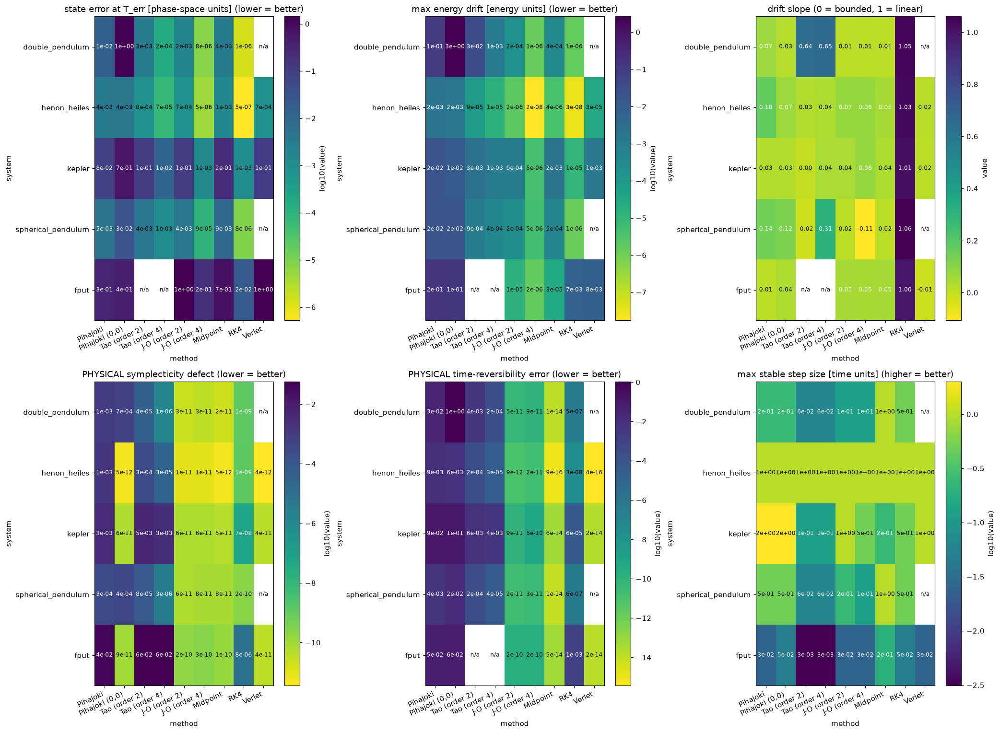

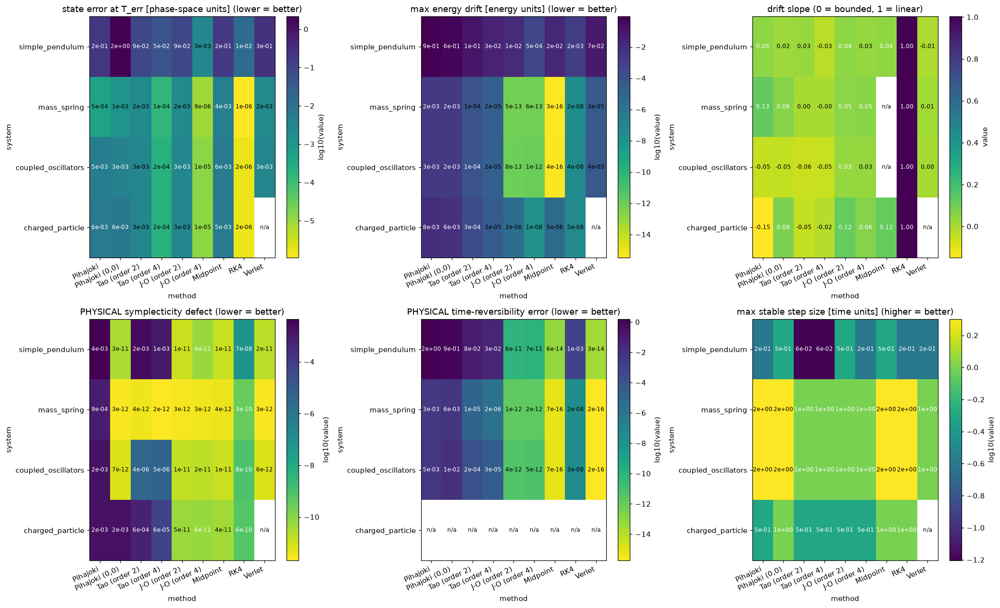

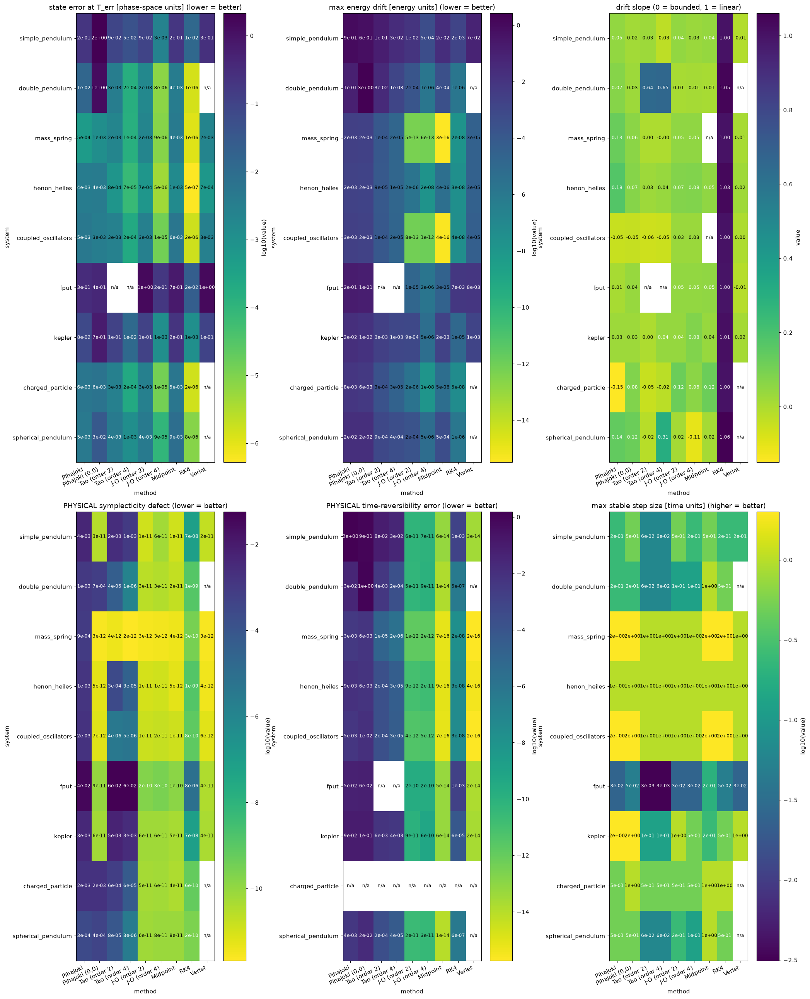

In [8]:
SYS_OK = list(TRUE)
LAB_OK = [l for l in ALL_LABELS if l in set(df_true["method"])]

# figure sets: main text (MAIN_SYSTEMS), annex (all the other systems), all (summary heatmaps only)
MAIN  = [k for k in MAIN_SYSTEMS if k in TRUE]
ANNEX = [k for k in SYS_OK if k not in MAIN]
SETS         = {"main": MAIN, "annex": ANNEX}                  # per-system figures
SETS_SUMMARY = {"main": MAIN, "annex": ANNEX, "all": SYS_OK}   # heatmaps and tables

def save_tag(fig, name, tag):
    (OUT / tag).mkdir(exist_ok=True)
    save(fig, f"{tag}/{name}")

panels = [
    ("err_Terr", "state error at T_err [phase-space units] (lower = better)", True, True),
    ("drift_max", "max energy drift [energy units] (lower = better)", True, True),
    ("drift_slope", "drift slope (0 = bounded, 1 = linear)", False, True),
    ("phys_symp_defect", "PHYSICAL symplecticity defect (lower = better)", True, True),
    ("rev_err", "PHYSICAL time-reversibility error (lower = better)", True, True),
    ("h_max_stable", "max stable step size [time units] (higher = better)", True, False),
]
for tag, keys in SETS_SUMMARY.items():
    if not keys:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(19, 2.4 * max(len(keys), 2) + 2))
    for ax, (col, title, log, lower) in zip(axes.ravel(), panels):
        heat(ax, piv(df_true, col, ridx=keys), title, log=log, lower_is_better=lower)
    plt.tight_layout()
    save_tag(fig, "true_heatmaps", tag)
    plt.show()

In [9]:
# Mean rank over systems (1 = best) on accuracy, energy drift, symplecticity, momentum and reversibility (NaN-safe)
rank_cols = ["err_Terr", "drift_max", "phys_symp_defect", "mom_drift_phys", "rev_err"]
R = {c: piv(df_true, c).rank(axis=1) for c in rank_cols}
R_mean = pd.concat(R.values()).groupby(level=0).mean().reindex(SYS_OK)
print("Mean rank per system (1 = best; NaN metrics are skipped):")
display(R_mean.round(2))

# ranks are computed within each system, so only the averaging over systems depends on the set
overall = pd.DataFrame({tag: R_mean.loc[keys].mean(axis=0)
                        for tag, keys in SETS_SUMMARY.items() if keys})
print("\nOverall mean rank (lower is better):")
display(overall.sort_values("all").round(2))
R_mean.to_csv(OUT / "mean_rank_per_system.csv")
overall.to_csv(OUT / "mean_rank_overall.csv")

Mean rank per system (1 = best; NaN metrics are skipped):


method,Pihajoki,"Pihajoki (0,0)",Tao (order 2),Tao (order 4),J-O (order 2),J-O (order 4),Midpoint,RK4,Verlet
system,,,,,,,,,
simple_pendulum,8.5,7.25,6.5,5.25,3,2.75,3.5,3.75,4.5
double_pendulum,7.25,7.75,5.75,4.5,2.75,2.25,3,2.75,NaN
mass_spring,7.5,6.25,6.5,3.75,4,3.5,4.75,4.5,4.25
henon_heiles,8.75,7,7,5.25,3.75,3,3.75,3.5,3
coupled_oscillators,8.5,6.5,6.25,5.5,3.5,3.5,3.75,4,3.5
fput,5.75,4.75,8.62,8.38,4.25,2.75,3.25,4,3.25
kepler,7.6,6.2,7.4,5.4,4.2,3.4,4.2,4,2.6
charged_particle,7.75,7.25,5.75,4.5,2.75,2.25,3,2.75,NaN
spherical_pendulum,6.3,6.9,6,4.8,2.9,2.5,3.9,2.7,NaN



Overall mean rank (lower is better):


,main,annex,all
method,,,
J-O (order 4),2.78,3,2.88
J-O (order 2),3.57,3.31,3.46
Verlet,2.95,4.08,3.52
RK4,3.39,3.75,3.55
Midpoint,3.62,3.75,3.68
Tao (order 4),5.66,4.75,5.26
Tao (order 2),6.96,6.25,6.64
"Pihajoki (0,0)",6.52,6.81,6.65
Pihajoki,7.13,8.06,7.54


## Extended-space preservation vs. the returned physical map

In [10]:
EXT_COLS = ["Hbar_drift_max", "Hbar_drift_slope", "gap_max", "gap_end", "ext_symp_defect", "phys_symp_defect",
            "mom_drift_ext", "mom_drift_phys", "ext_rev_err", "rev_err"]
df_ext = df_true[df_true["ext_symp_defect"].notna()]
print("Extended-space metrics next to their physical counterparts (extended methods only)")
display(df_ext.set_index(["system", "method"])[EXT_COLS].round(4))

# Median over systems: how far is the physical map from the extended map's properties?
cols = ["ext_symp_defect", "phys_symp_defect", "Hbar_drift_max", "drift_max", "gap_max"]
order = [l for l in LAB_OK if l in set(df_ext["method"])]
for tag, keys in SETS_SUMMARY.items():
    if keys:
        print(f"Median over systems [{tag}]")
        display(df_ext[df_ext["system"].isin(keys)].groupby("method")[cols].median().reindex(order))

Extended-space metrics next to their physical counterparts (extended methods only)


Hbar_drift_max  Hbar_drift_slope  gap_max  gap_end  ext_symp_defect  phys_symp_defect  mom_drift_ext  mom_drift_phys  ext_rev_err  rev_err
system              method                                                                                                                                                    
simple_pendulum     Pihajoki                 0.107           -0.0112    0.467    0.259           0.0144            0.0045            NaN             NaN        0.497     1.54
                    Pihajoki (0,0)           0.919             0.829     4.55     4.48                0                 0            NaN             NaN         2.16     0.88
                    Tao (order 2)           0.0176            0.0396   0.0401   0.0065                0            0.0024            NaN             NaN            0     0.08
                    Tao (order 4)           0.0206            0.0211   0.0058   0.0018                0             0.001            NaN             NaN            0   0.0298
                    J-O (order 2)           0.0213            0.0346        0        0                0                 0            NaN             NaN            0        0
                    J-O (order 4)            0.001             0.021        0        0                0                 0            NaN             NaN            0        0
double_pendulum     Pihajoki                0.0044            0.0351    0.133   0.0781           0.0015             0.001            NaN             NaN        0.127   0.0318
                    Pihajoki (0,0)           0.065            0.0598     3.75     2.15                0            0.0007            NaN             NaN        0.473     1.07
                    Tao (order 2)           0.0004            0.0914   0.0126   0.0095                0                 0            NaN             NaN            0    0.004
                    Tao (order 4)                0             0.128   0.0005   0.0004                0                 0            NaN             NaN            0   0.0002
                    J-O (order 2)           0.0003            0.0066        0        0                0                 0            NaN             NaN            0        0
                    J-O (order 4)                0           -0.0246        0        0                0                 0            NaN             NaN            0        0
mass_spring         Pihajoki                0.0002             0.215   0.0182   0.0019           0.0013            0.0009            NaN             NaN        0.018   0.0034
                    Pihajoki (0,0)          0.0001            0.0491   0.0104   0.0027                0                 0            NaN             NaN        0.008   0.0056
                    Tao (order 2)                0           -0.0115   0.0005   0.0001                0                 0            NaN             NaN            0        0
                    Tao (order 4)                0           -0.0245   0.0001        0                0                 0            NaN             NaN            0        0
                    J-O (order 2)                0            0.0452        0        0                0                 0            NaN             NaN            0        0
                    J-O (order 4)                0            0.0791        0        0                0                 0            NaN             NaN            0        0
henon_heiles        Pihajoki                0.0001             0.349   0.0167   0.0028           0.0021            0.0014            NaN             NaN       0.0208   0.0087
                    Pihajoki (0,0)          0.0001             0.406    0.025   0.0228                0                 0            NaN             NaN       0.0083   0.0058
                    Tao (order 2)                0              0.12   0.0005   0.0003                0            0.0003            NaN             NaN            0   0.0002
           

Median over systems [main]


,ext_symp_defect,phys_symp_defect,Hbar_drift_max,drift_max,gap_max
method,,,,,
Pihajoki,0.00213,0.00141,0.00249,0.0191,0.0909
"Pihajoki (0,0)",5.77e-11,9.22e-11,0.0104,0.0182,0.129
Tao (order 2),7.6e-11,0.000167,0.000409,0.00175,0.00383
Tao (order 4),1.36e-10,1.64e-05,6.96e-05,0.000744,0.000445
J-O (order 2),6.71e-11,6.34e-11,0.000348,0.000175,1.59e-12
J-O (order 4),1.38e-10,6.45e-11,3.27e-06,1.63e-06,2.06e-12


Median over systems [annex]


,ext_symp_defect,phys_symp_defect,Hbar_drift_max,drift_max,gap_max
method,,,,,
Pihajoki,0.00205,0.00176,0.00035,0.00535,0.026
"Pihajoki (0,0)",2.64e-11,1.89e-11,0.000108,0.00404,0.0171
Tao (order 2),4.05e-11,0.000323,3.32e-06,0.000182,0.000551
Tao (order 4),7.77e-11,3.1e-05,4.48e-07,2.13e-05,8.24e-05
J-O (order 2),2.24e-11,1.33e-11,2.37e-06,1.18e-06,2.34e-13
J-O (order 4),3.75e-11,3.8e-11,1.4e-08,7e-09,2.9e-13


Median over systems [all]


,ext_symp_defect,phys_symp_defect,Hbar_drift_max,drift_max,gap_max
method,,,,,
Pihajoki,0.00213,0.00175,0.00177,0.0182,0.0658
"Pihajoki (0,0)",4.73e-11,5.79e-11,0.000954,0.0128,0.0733
Tao (order 2),6.77e-11,0.000167,0.000181,0.000596,0.0013
Tao (order 4),1.24e-10,1.75e-05,2.28e-05,0.000218,0.000262
J-O (order 2),3.95e-11,2.52e-11,2.9e-05,1.45e-05,1.54e-12
J-O (order 4),7.06e-11,5.83e-11,2.87e-06,1.44e-06,1.58e-12


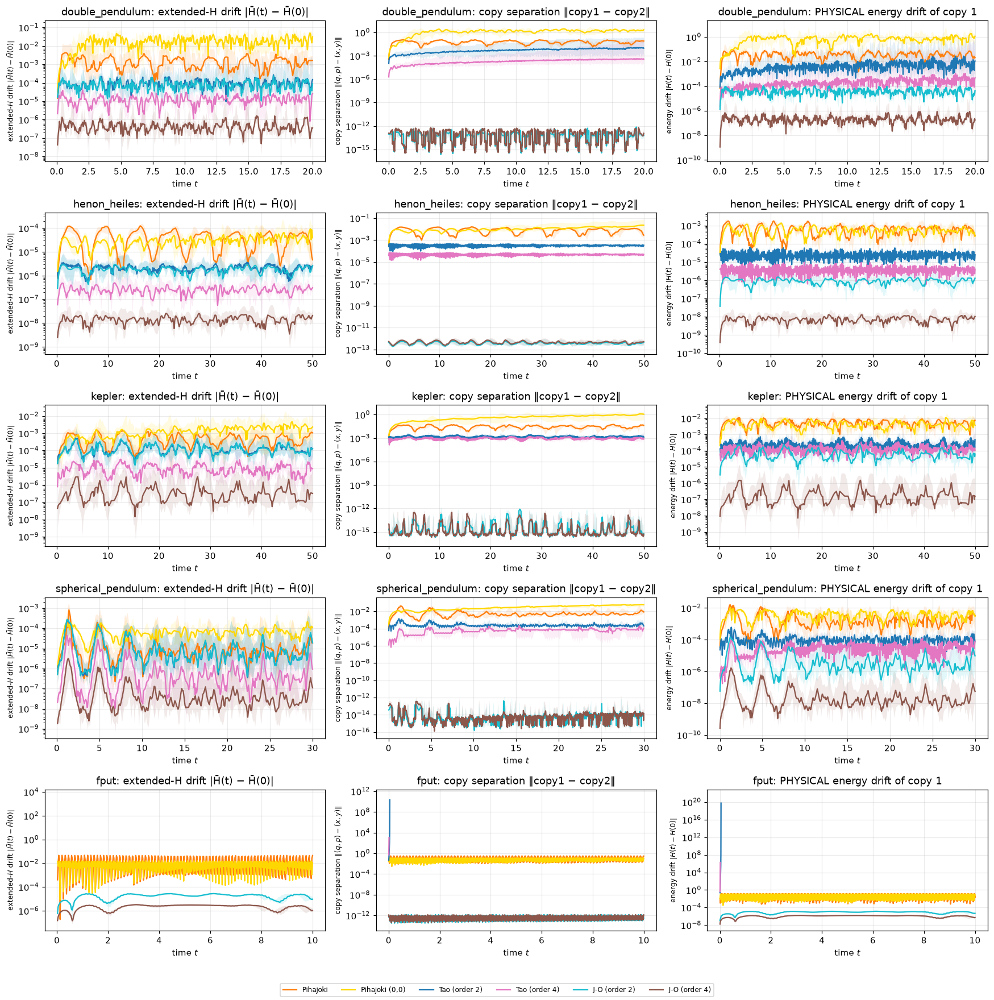

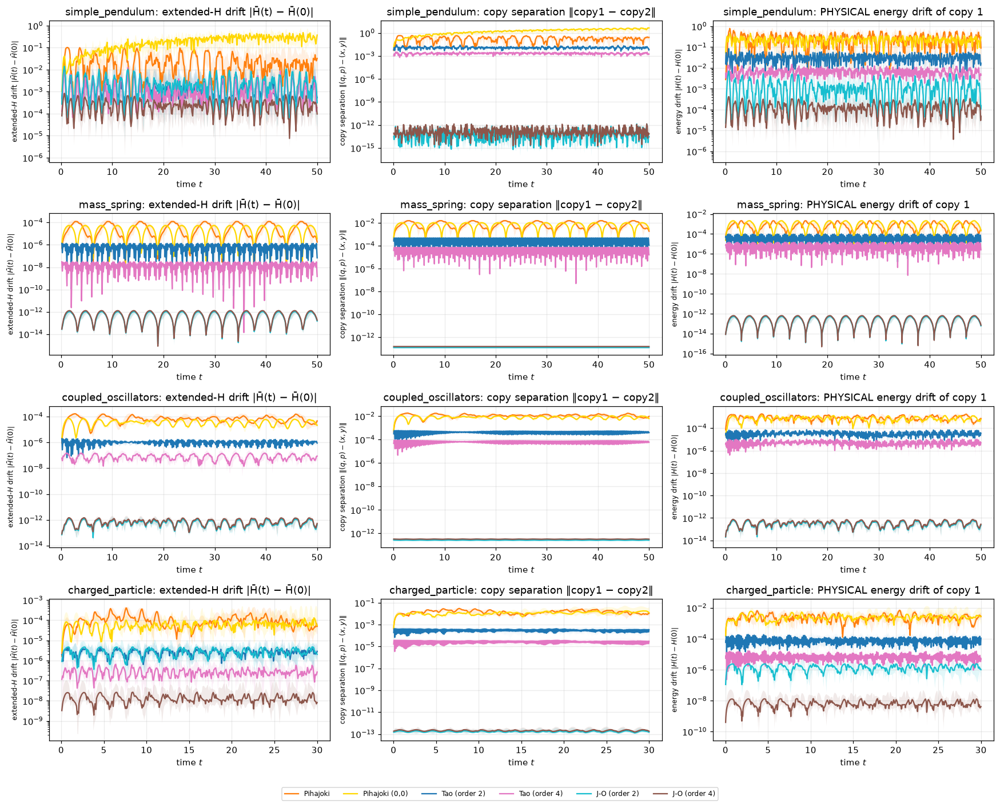

In [11]:
# H-bar drift, copy separation and physical drift of every extended method, one row per system
EXT_LAB = [l for l in LAB_OK if methods_for(SYS_OK[0]).get(l, ("",))[0] in EXT_NAMES]

def fig_extended_timeseries(keys, tag):
    fig, axes = plt.subplots(len(keys), 3, figsize=(16, 3.2 * len(keys)), squeeze=False)
    for row, key in enumerate(keys):
        res = TRUE[key]
        t = res["t"]
        for label, r in res["runs"].items():
            e = r["ext"]
            if e is None:
                continue
            ti = t[r["idx"]]
            band(axes[row, 0], ti, e["Hbar_drift"], label)
            band(axes[row, 1], t, e["gap"], label)
            band(axes[row, 2], t, r["drift"], label)
        axes[row, 0].set_title(f"{key}: extended-H drift |H̄(t) − H̄(0)|")
        axes[row, 1].set_title(f"{key}: copy separation ‖copy1 − copy2‖")
        axes[row, 2].set_title(f"{key}: PHYSICAL energy drift of copy 1")
        for ax, yl in zip(axes[row], (LBL["Hbar"], LBL["gap"], LBL["drift"])):
            ax.set_xlabel(LBL["t"])
            ax.set_ylabel(yl, fontsize=8)
    h_, l_ = axes[0, 0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=len(l_))
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    save_tag(fig, "true_extended_timeseries", tag)
    plt.show()

for tag, keys in SETS.items():
    if keys:
        fig_extended_timeseries(keys, tag)

### Which physical projection to return?

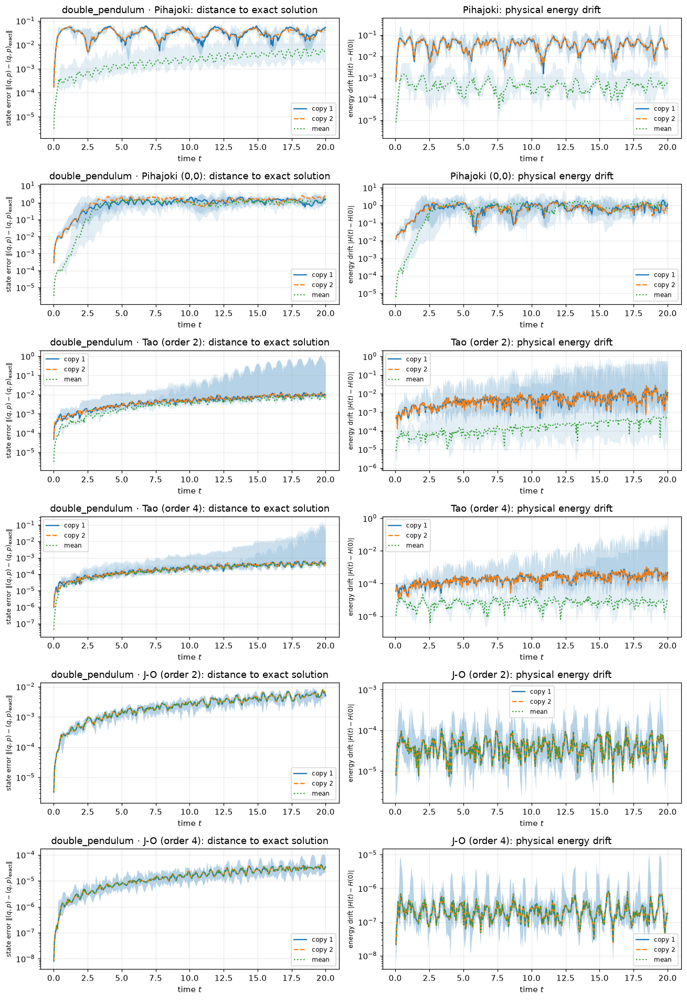

In [12]:
fs = FOCUS_SYSTEM if FOCUS_SYSTEM in TRUE else SYS_OK[0]
res = TRUE[fs]
t = res["t"]
ext_runs = {l: r for l, r in res["runs"].items() if r["ext"] is not None}
fig, axes = plt.subplots(len(ext_runs), 2, figsize=(12, 2.9 * len(ext_runs)), squeeze=False)
for row, (label, r) in enumerate(ext_runs.items()):
    e = r["ext"]
    ti = t[r["idx"]]
    for nm, err, dr, ls in (("copy 1", r["err"], r["drift"][:, r["idx"]], "-"),
                            ("copy 2", r["err_copy2"], e["drift_copy2"], "--"),
                            ("mean", r["err_mean"], e["drift_mean"], ":")):
        band(axes[row, 0], t, err, nm, ls=ls)
        band(axes[row, 1], ti, dr, nm, ls=ls)
    axes[row, 0].set_title(f"{fs} · {label}: distance to exact solution")
    axes[row, 1].set_title(f"{label}: physical energy drift")
    for ax, yl in zip(axes[row], (LBL["err"], LBL["drift"])):
        ax.set_xlabel(LBL["t"])
        ax.set_ylabel(yl, fontsize=8)
        ax.legend()
plt.tight_layout()
save_tag(fig, "true_projection_choice", "main")
plt.show()

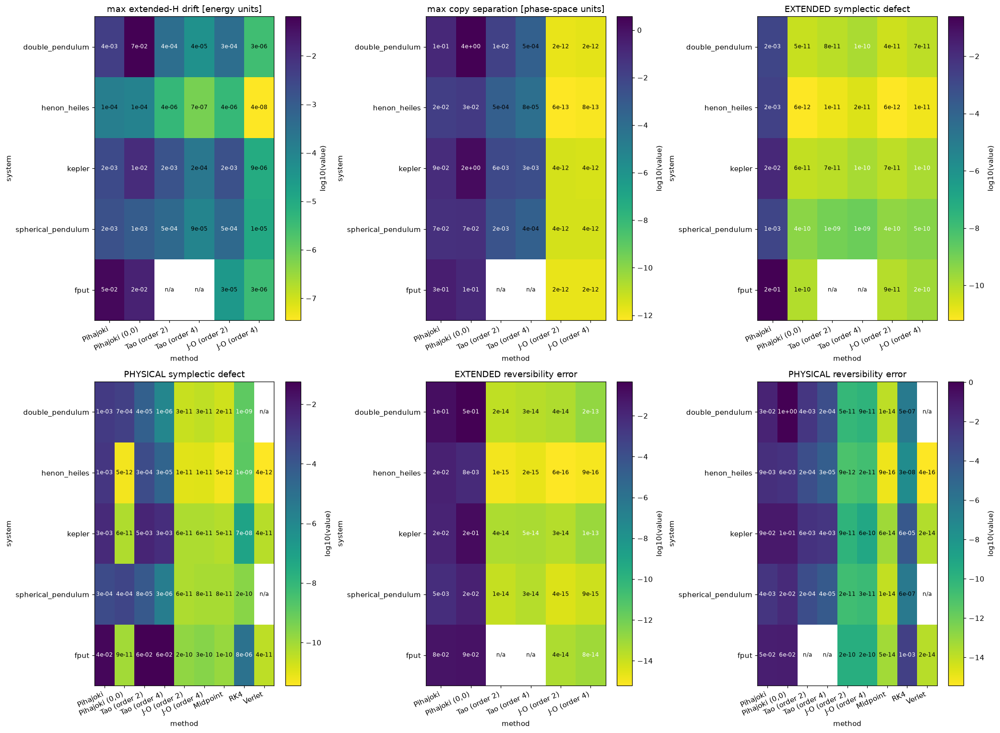

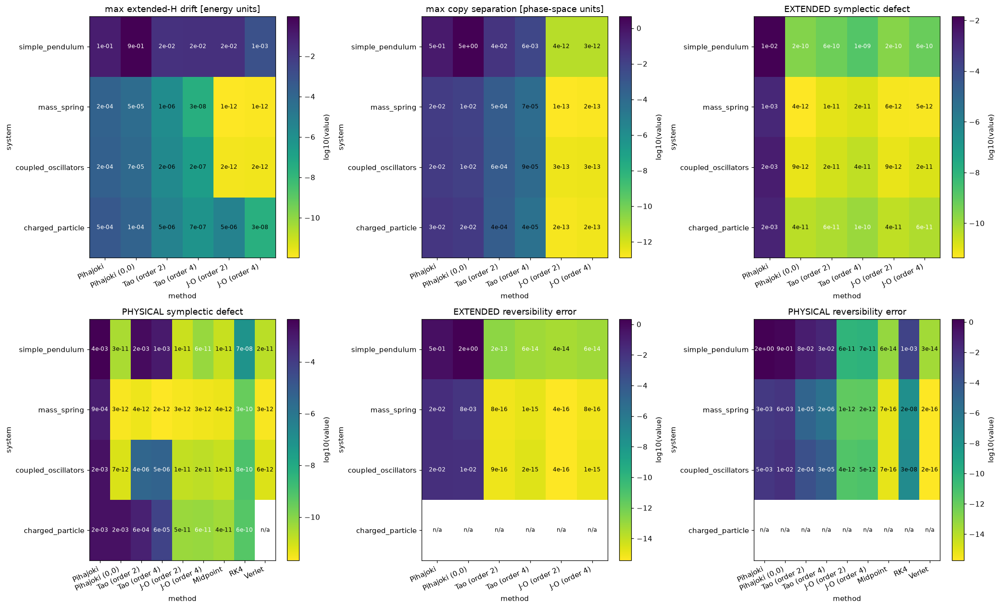

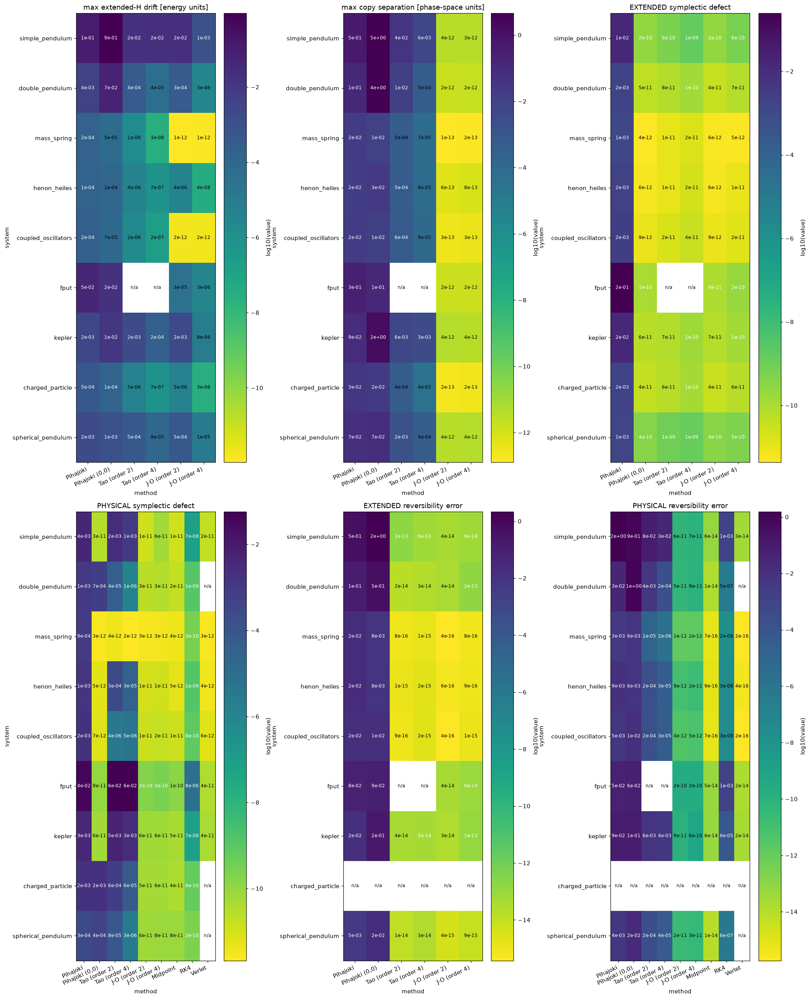

In [13]:
panels = [
    ("Hbar_drift_max", "max extended-H drift [energy units]", True, True),
    ("gap_max", "max copy separation [phase-space units]", True, True),
    ("ext_symp_defect", "EXTENDED symplectic defect", True, True),
    ("phys_symp_defect", "PHYSICAL symplectic defect", True, True),
    ("ext_rev_err", "EXTENDED reversibility error", True, True),
    ("rev_err", "PHYSICAL reversibility error", True, True),
]
for tag, keys in SETS_SUMMARY.items():
    if not keys:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(19, 2.4 * max(len(keys), 2) + 2))
    for ax, (col, title, log, lower) in zip(axes.ravel(), panels):
        heat(ax, piv(df_true, col, ridx=keys,
                     rcol=EXT_LAB if col.startswith(("Hbar", "gap", "ext")) else None),
             title, log=log, lower_is_better=lower)
    plt.tight_layout()
    save_tag(fig, "true_extended_heatmaps", tag)
    plt.show()

## Energy drift and state error over time

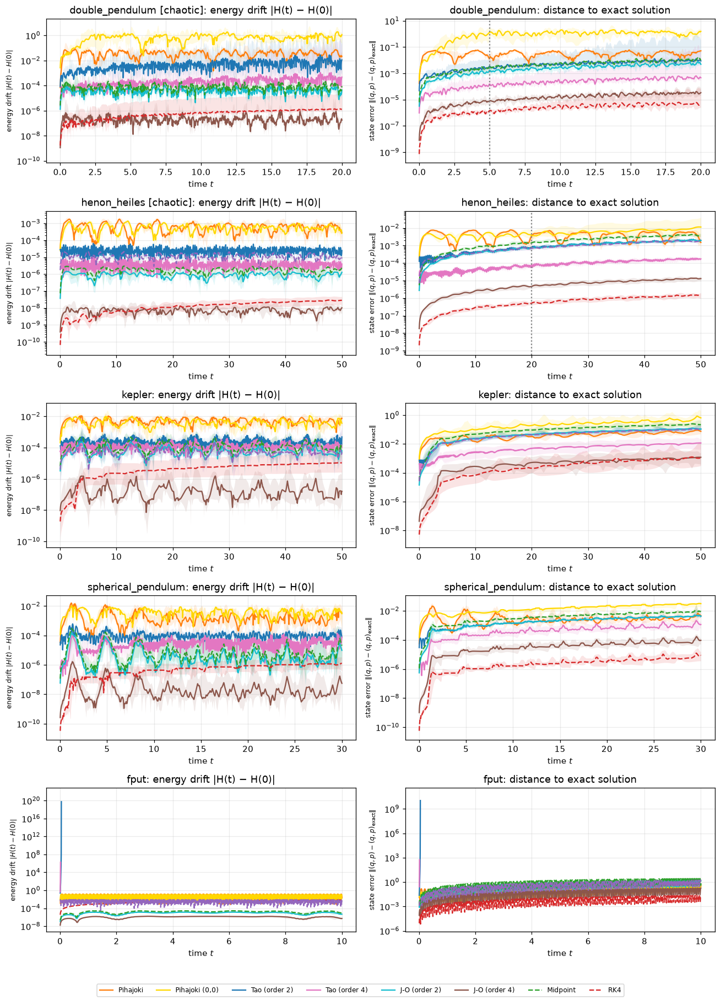

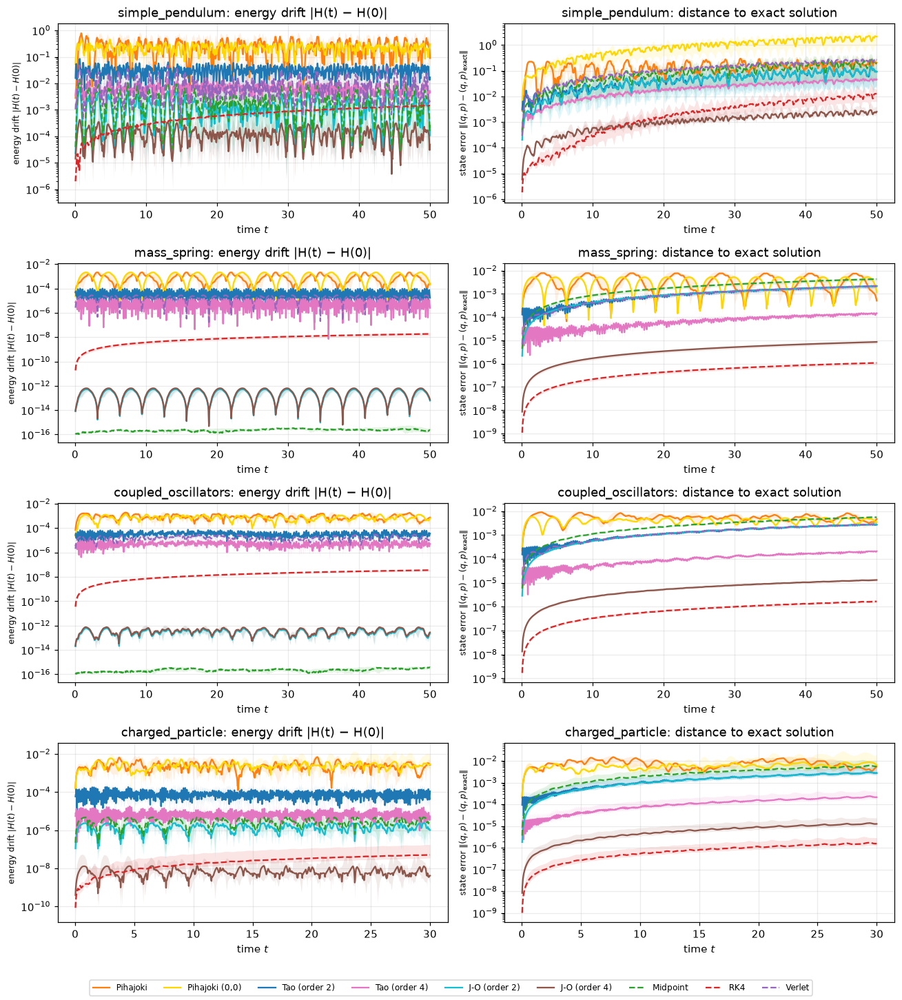

In [14]:
def fig_timeseries(keys, tag):
    fig, axes = plt.subplots(len(keys), 2, figsize=(12, 3.3 * len(keys)), squeeze=False)
    for row, key in enumerate(keys):
        res = TRUE[key]
        t, cfg = res["t"], res["cfg"]
        flag = " [chaotic]" if cfg["chaotic"] else ""
        for label, r in res["runs"].items():
            band(axes[row, 0], t, r["drift"], label)
            band(axes[row, 1], t, r["err"], label)
        axes[row, 0].set_title(f"{key}{flag}: energy drift |H(t) − H(0)|")
        axes[row, 1].set_title(f"{key}: distance to exact solution")
        if cfg["chaotic"]:
            axes[row, 1].axvline(cfg["T_err"], color="gray", ls=":")
        for ax, yl in zip(axes[row], (LBL["drift"], LBL["err"])):
            ax.set_xlabel(LBL["t"])
            ax.set_ylabel(yl, fontsize=8)
    h_, l_ = axes[0, 0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=len(l_))
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    save_tag(fig, "true_timeseries", tag)
    plt.show()

for tag, keys in SETS.items():
    if keys:
        fig_timeseries(keys, tag)

## Convergence, error-vs-cost and wall-clock

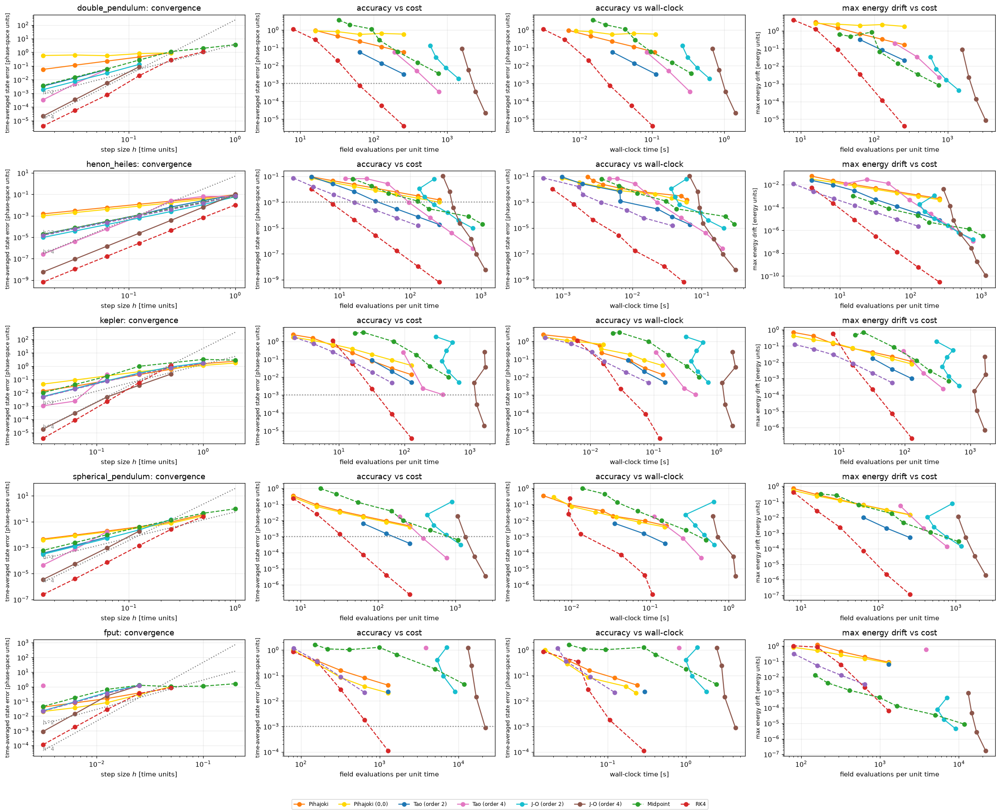

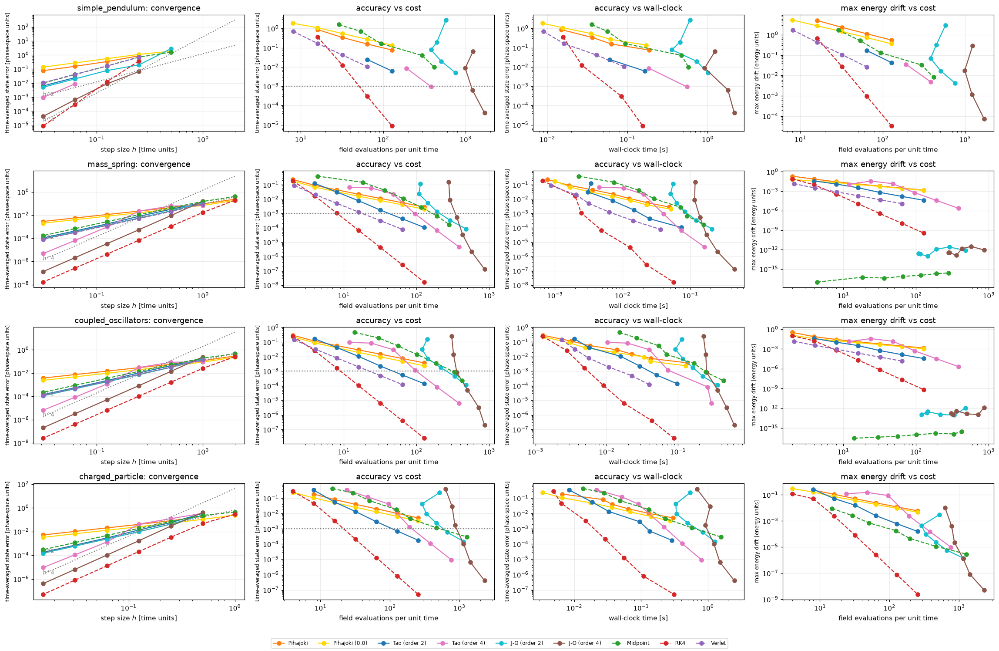

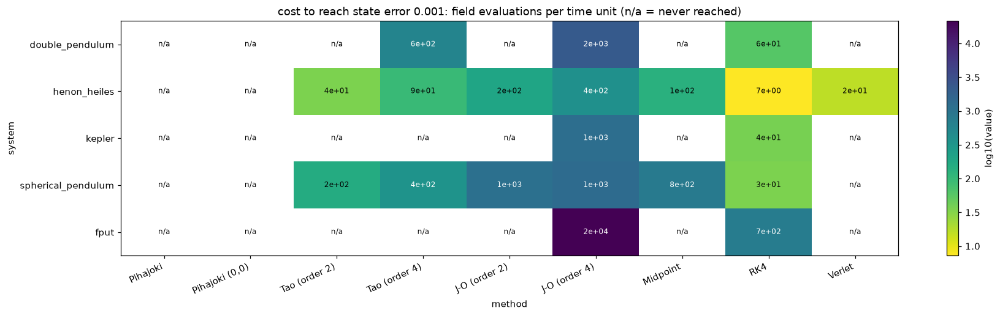

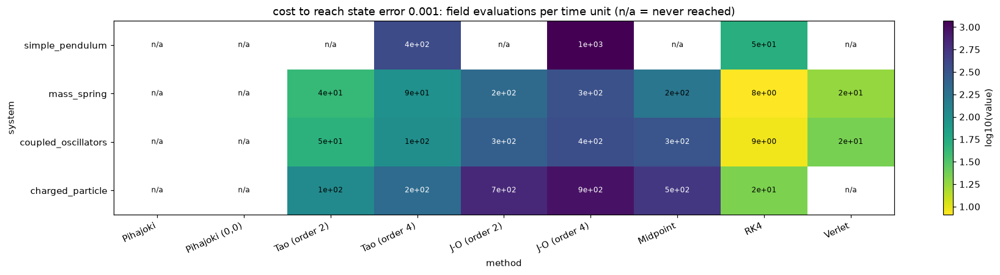

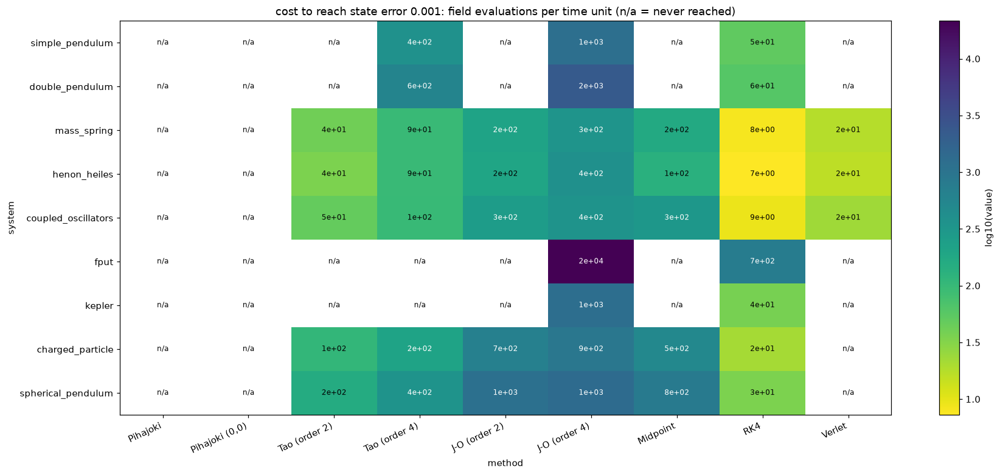

In [15]:
def fig_convergence(keys, tag):
    fig, axes = plt.subplots(len(keys), 4, figsize=(21, 3.4 * len(keys)), squeeze=False)
    for row, key in enumerate(keys):
        sweep = TRUE[key]["sweep"]
        for label, pts in sweep.items():
            P = np.array([(p["h"], p["err"], p["evals"], p["seconds"], p["drift"]) for p in pts
                          if p["stable"] and np.isfinite(p["err"]) and p["err"] > 0])
            if len(P) == 0:
                continue
            h, e, w, s, dr = P.T
            st = {k: v for k, v in sty(label).items() if k != "lw"}
            axes[row, 0].loglog(h, e, marker="o", label=label, **st)
            axes[row, 1].loglog(w, e, marker="o", label=label, **st)
            axes[row, 2].loglog(s, e, marker="o", label=label, **st)
            axes[row, 3].loglog(w, np.maximum(dr, 1e-17), marker="o", label=label, **st)
        hh = np.array(sorted({p["h"] for pts in sweep.values() for p in pts}))[::-1]
        allE = [p["err"] for pts in sweep.values() for p in pts
                if p["stable"] and np.isfinite(p["err"]) and p["err"] > 0]
        if allE:
            e0, h0 = np.median(allE), hh[len(hh) // 2]
            for order in (2, 4):
                axes[row, 0].loglog(hh, e0 * (hh / h0) ** order, ":", color="gray")
                axes[row, 0].text(hh[-1], e0 * (hh[-1] / h0) ** order, f"h^{order}",
                                  color="gray", fontsize=8)
        axes[row, 1].axhline(COST_TARGET, color="gray", ls=":")
        axes[row, 0].set_title(f"{key}: convergence")
        axes[row, 0].set_xlabel(LBL["h"])
        axes[row, 0].set_ylabel("time-averaged state error [phase-space units]", fontsize=8)
        axes[row, 1].set_title("accuracy vs cost")
        axes[row, 1].set_xlabel(LBL["cost"])
        axes[row, 1].set_ylabel("time-averaged state error [phase-space units]", fontsize=8)
        axes[row, 2].set_title("accuracy vs wall-clock")
        axes[row, 2].set_xlabel(LBL["sec"])
        axes[row, 2].set_ylabel("time-averaged state error [phase-space units]", fontsize=8)
        axes[row, 3].set_title("max energy drift vs cost")
        axes[row, 3].set_xlabel(LBL["cost"])
        axes[row, 3].set_ylabel("max energy drift [energy units]", fontsize=8)
    h_, l_ = axes[0, 0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=len(l_))
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    save_tag(fig, "true_convergence", tag)
    plt.show()

for tag, keys in SETS.items():
    if keys:
        fig_convergence(keys, tag)

for tag, keys in SETS_SUMMARY.items():
    if not keys:
        continue
    fig, ax = plt.subplots(figsize=(1.6 * len(LAB_OK) + 2, 0.6 * len(keys) + 1.8))
    heat(ax, piv(df_true, "cost_target", ridx=keys),
         f"cost to reach state error {COST_TARGET:g}: field evaluations per time unit (n/a = never reached)")
    plt.tight_layout()
    save_tag(fig, "true_cost_target", tag)
    plt.show()

## J-O implicit-solver diagnostics

In [16]:
JO_VARIANTS = {"order 2 / newton": (2, "newton"), "order 2 / broyden": (2, "broyden"),
               "order 4 / newton": (4, "newton"), "order 4 / broyden": (4, "broyden")}


def jo_run(res, order, solver, tol=None, T=None, n=None):
    system, d, Y0, f_flat = res["system"], res["d"], res["Y0"], res["f_flat"]
    N = len(Y0)
    T = res["cfg"]["T"] if T is None else T
    n = res["cfg"]["steps"] if n is None else n
    kw = {**JO_KW, "solver": solver, "order": order}
    if tol is not None:
        kw["tol"] = tol
    cf, st = Counted(f_flat, weight=N), {}
    t0 = time.perf_counter()
    _, y = semiexplicit(cf, (0.0, T), stack(Y0, d), n, stats=st, **kw)
    sec = time.perf_counter() - t0
    traj = unstack(y, N, d)
    return dict(stats=st, seconds=sec, evals=cf.n / (N * n), traj=traj, n=n,
                drift=max_over_time(energy_drift(res["H"], traj)) if np.isfinite(traj).all() else np.inf)


JO_DIAG, rows = {}, []
for key in SYS_OK:
    JO_DIAG[key] = {}
    for lab, (order, solver) in JO_VARIANTS.items():
        try:
            r = jo_run(TRUE[key], order, solver)
        except Exception as e:
            print(f"   {key}/{lab}: failed: {type(e).__name__}: {e}")
            continue
        JO_DIAG[key][lab] = r
        st = r["stats"]
        rows.append(dict(
            system=key, variant=lab, iters_mean=np.mean(st["iterations"]), iters_p95=np.percentile(st["iterations"], 95),
            iters_max=np.max(st["iterations"]), nfail=st["n_not_converged"],
            phi_per_step=st["n_phi_evals"] / r["n"], evals_per_step=r["evals"],
            residual_max=np.max(st["residual"]), defect_max=st["max_defect"],
            drift_max=r["drift"], seconds=r["seconds"]))
df_jo = pd.DataFrame(rows)
df_jo.to_csv(OUT / "jo_solver_diagnostics.csv", index=False)
display(df_jo.set_index(["system", "variant"]).round(4))

iters_mean  iters_p95  iters_max  nfail  phi_per_step  evals_per_step  residual_max  defect_max  drift_max  seconds
system              variant                                                                                                                               
simple_pendulum     order 2 / newton         8.58          9          9      0          9.58            28.7             0           0     0.0106     3.08
                    order 2 / broyden        7.95          8          8      0          8.95            26.9             0           0     0.0106      2.9
                    order 4 / newton         6.25          7          7      0          7.25            65.3             0           0     0.0005     6.75
                    order 4 / broyden           6          6          6      0             7              63             0           0     0.0005     6.58
double_pendulum     order 2 / newton         5.29          7          7      0          6.29            18.9             0           0     0.0002     3.75
                    order 2 / broyden        5.05          6          6      0          6.05            18.1             0           0     0.0002     3.88
                    order 4 / newton         3.52          5          5      0          4.52            40.7             0           0          0     8.58
                    order 4 / broyden        3.41          4          5      0          4.41            39.7             0           0          0     7.42
mass_spring         order 2 / newton            5          5          5      0             6              18             0           0          0    0.564
                    order 2 / broyden           4          4          4      0             5              15             0           0          0    0.552
                    order 4 / newton            3          3          3      0             4              36             0           0          0     1.03
                    order 4 / broyden           3          3          3      0             4              36             0           0          0     1.07
henon_heiles        order 2 / newton            5          5          5      0             6              18             0           0          0    0.634
                    order 2 / broyden        4.93          5          5      0          5.93            17.8             0           0          0    0.692
                    order 4 / newton            3          3          3      0             4              36             0           0          0     1.17
                    order 4 / broyden           3          3          3      0             4              36             0           0          0     1.21
coupled_oscillators order 2 / newton            5          5          5      0             6              18             0           0          0     1.12
                    order 2 / broyden           4          4          4      0             5              15             0           0          0     1.09
                    order 4 / newton            3          3          3      0             4              36             0           0          0     2.08
                    order 4 / broyden           3          3          3      0             4              36             0           0          0     2.03
fput                order 2 / newton         10.8         11         11      0          11.8            35.5             0           0          0     12.5
                    order 2 / broyden        7.45          8          8      0          8.45            25.3             0           0          0     8.65
                    order 4 / newton         8.87          9          9      0          9.87            88.8             0           0          0     30.3
                    order 4 / broyden        5.72          7          7      0          6.72            60.5             0           0          0     27.5
kepler   

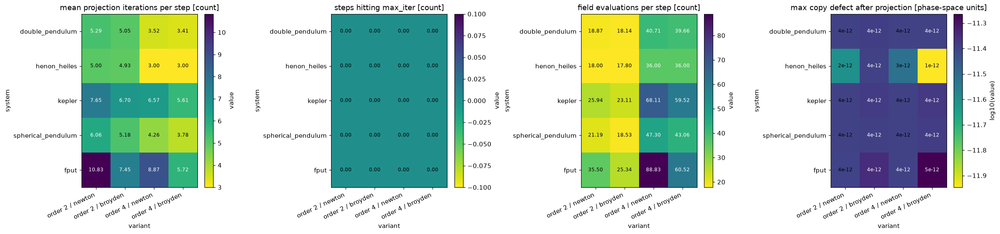

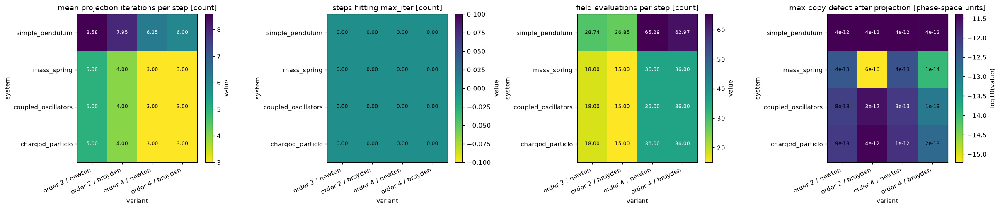

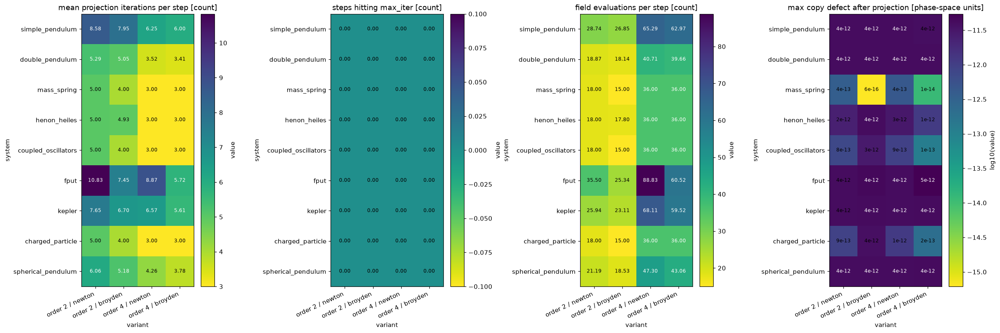

,iters,nfail,defect,drift,evals
tol,,,,,
1e-06,1.51,0,0,0.0003,7.53
1e-09,3.31,0,0,0.0002,12.9
1e-12,5.29,0,0,0.0002,18.9
1e-14,6.59,0,0,0.0002,22.8


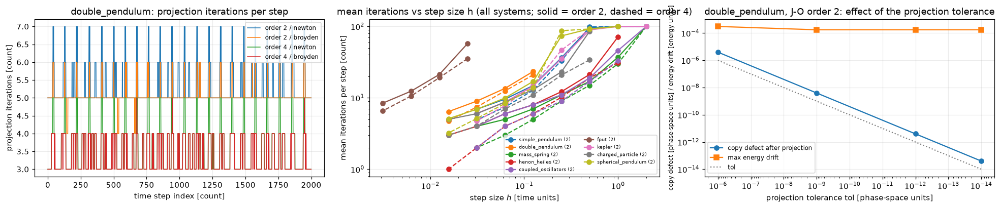

In [17]:
VAR = list(JO_VARIANTS)
jo_panels = [("iters_mean", "mean projection iterations per step [count]", False),
             ("nfail", "steps hitting max_iter [count]", False),
             ("evals_per_step", "field evaluations per step [count]", False),
             ("defect_max", "max copy defect after projection [phase-space units]", True)]
for tag, keys in SETS_SUMMARY.items():
    if not keys:
        continue
    fig, axes = plt.subplots(1, 4, figsize=(22, 0.55 * len(keys) + 2.5))
    for ax, (col, title, log) in zip(axes, jo_panels):
        heat(ax, df_jo.pivot(index="system", columns="variant", values=col).reindex(index=keys, columns=VAR),
             title, log=log, lower_is_better=True)
    plt.tight_layout()
    save_tag(fig, "jo_solver_heatmaps", tag)
    plt.show()

# iterations per step along the run, and as a function of the step size
fs = FOCUS_SYSTEM if FOCUS_SYSTEM in JO_DIAG else SYS_OK[0]
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for lab, r in JO_DIAG[fs].items():
    axes[0].plot(r["stats"]["iterations"], label=lab, lw=1)
axes[0].set_title(f"{fs}: projection iterations per step")
axes[0].set_xlabel("time step index [count]")
axes[0].set_ylabel("projection iterations [count]")
axes[0].legend()
for key in SYS_OK:
    for label in ("J-O (order 2)", "J-O (order 4)"):
        pts = [p for p in TRUE[key]["sweep"].get(label, []) if np.isfinite(p["iters"])]
        if pts:
            axes[1].loglog([p["h"] for p in pts], [max(p["iters"], 1e-2) for p in pts],
                           marker="o", ls="-" if "2" in label else "--", color=f"C{SYS_OK.index(key) % 10}",
                           label=f"{key} ({label[-2]})" if label.endswith("2)") else None)
axes[1].set_title("mean iterations vs step size h (all systems; solid = order 2, dashed = order 4)")
axes[1].set_xlabel(LBL["h"])
axes[1].set_ylabel("mean iterations per step [count]")
axes[1].legend(fontsize=6, ncol=2)

# tolerance sweep on the focus system (order 2, newton)
rows = []
for tol in JO_TOLS:
    r = jo_run(TRUE[fs], 2, "newton", tol=tol)
    st = r["stats"]
    rows.append(dict(tol=tol, iters=np.mean(st["iterations"]), nfail=st["n_not_converged"],
                     defect=st["max_defect"], drift=r["drift"], evals=r["evals"]))
df_tol = pd.DataFrame(rows)
display(df_tol.set_index("tol").round(4))
axes[2].loglog(df_tol["tol"], df_tol["defect"], "o-", label="copy defect after projection")
axes[2].loglog(df_tol["tol"], np.maximum(df_tol["drift"], 1e-17), "s-", label="max energy drift")
axes[2].loglog(df_tol["tol"], df_tol["tol"], ":", color="gray", label="tol")
axes[2].invert_xaxis()
axes[2].set_title(f"{fs}, J-O order 2: effect of the projection tolerance")
axes[2].set_xlabel("projection tolerance tol [phase-space units]")
axes[2].set_ylabel("copy defect [phase-space units] / energy drift [energy units]", fontsize=8)
axes[2].legend()
plt.tight_layout()
save_tag(fig, "jo_solver_focus", "main")
plt.show()

## Momentum and reversibility

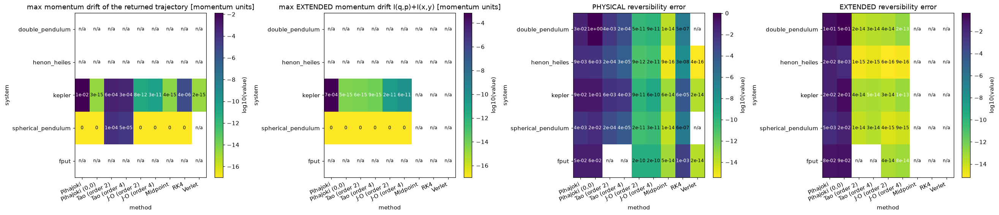

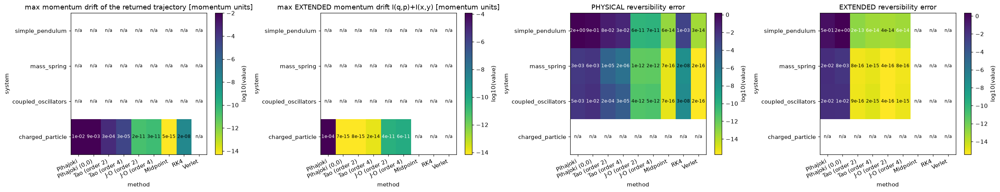

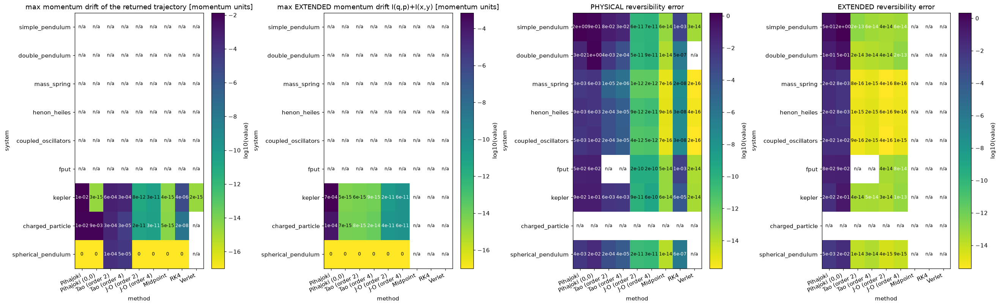

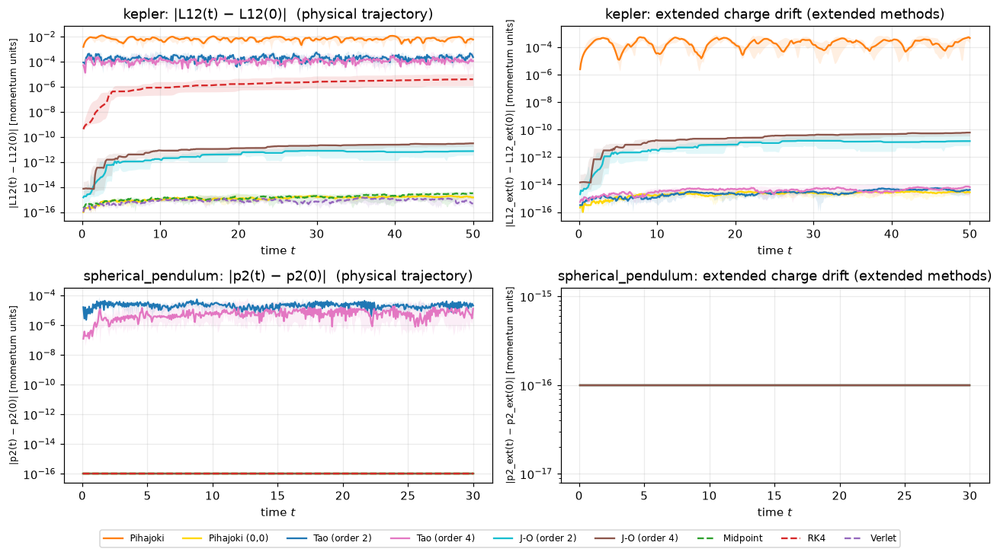

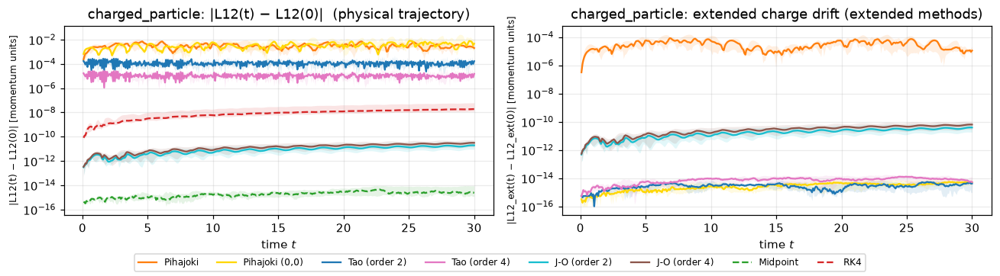

In [18]:
panels = [
    ("mom_drift_phys", "max momentum drift of the returned trajectory [momentum units]", True, True),
    ("mom_drift_ext", "max EXTENDED momentum drift I(q,p)+I(x,y) [momentum units]", True, True),
    ("rev_err", "PHYSICAL reversibility error", True, True),
    ("ext_rev_err", "EXTENDED reversibility error", True, True),
]
for tag, keys in SETS_SUMMARY.items():
    if not keys:
        continue
    fig, axes = plt.subplots(1, 4, figsize=(24, 0.55 * len(keys) + 2.5))
    for ax, (col, title, log, lower) in zip(axes, panels):
        heat(ax, piv(df_true, col, ridx=keys), title, log=log, lower_is_better=lower)
    plt.tight_layout()
    save_tag(fig, "true_momentum_reversibility", tag)
    plt.show()


def fig_momentum(keys, tag):
    fig, axes = plt.subplots(len(keys), 2, figsize=(12, 3.3 * len(keys)), squeeze=False)
    for row, key in enumerate(keys):
        res = TRUE[key]
        for label, r in res["runs"].items():
            ti = res["t"][r["idx"]]
            band(axes[row, 0], ti, r["mom"], label)
            if r["ext"] is not None and "mom_ext" in r["ext"]:
                band(axes[row, 1], ti, r["ext"]["mom_ext"], label)
        nm = res["inv"]["name"]
        axes[row, 0].set_title(f"{key}: |{nm}(t) − {nm}(0)|  (physical trajectory)")
        axes[row, 1].set_title(f"{key}: extended charge drift (extended methods)")
        axes[row, 0].set_ylabel(f"|{nm}(t) − {nm}(0)| [momentum units]", fontsize=8)
        axes[row, 1].set_ylabel(f"|{nm}_ext(t) − {nm}_ext(0)| [momentum units]", fontsize=8)
        for ax in axes[row]:
            ax.set_xlabel(LBL["t"])
    h_, l_ = axes[0, 0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=len(l_))
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    save_tag(fig, "true_momentum_timeseries", tag)
    plt.show()


any_inv = False
for tag, keys in SETS.items():
    ks = [k for k in keys if TRUE[k]["inv"] is not None]   # only systems with a detected invariant
    if ks:
        any_inv = True
        fig_momentum(ks, tag)
if not any_inv:
    print("no momentum-like invariant detected on any system")

## Tao restraint ω on every system

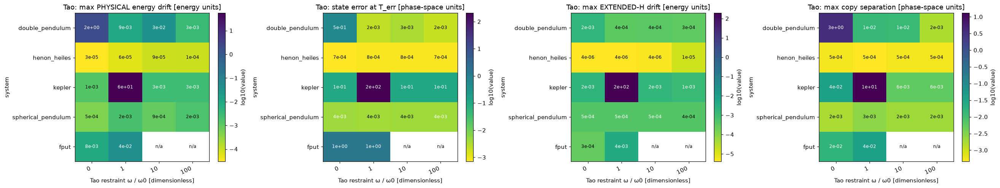

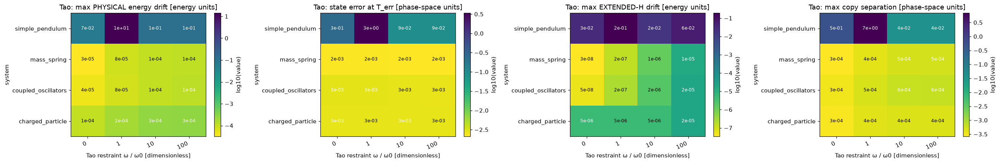

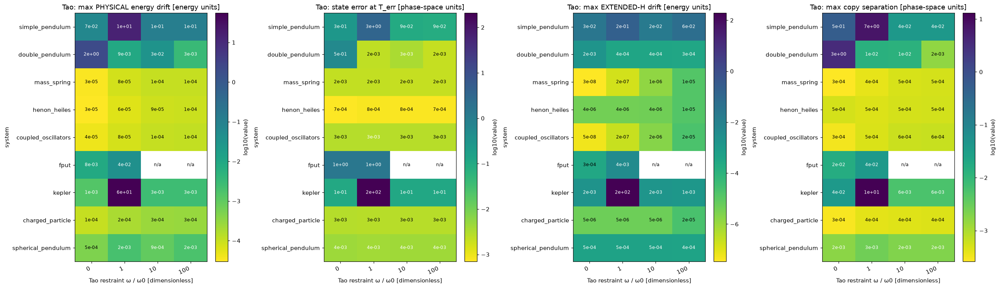

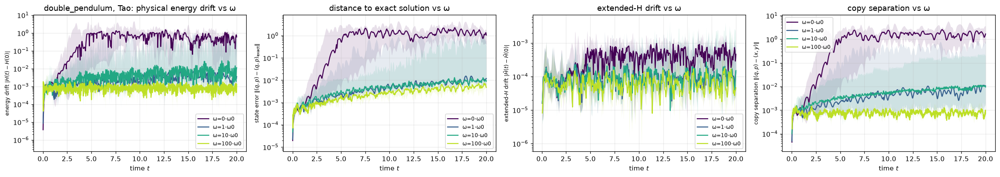

In [19]:
def omega_sweep(key):
    res = TRUE[key]
    system, d, cfg = res["system"], res["d"], res["cfg"]
    N, n = len(res["Y0"]), cfg["steps"]
    out = {}
    for rel in OMEGAS_REL:
        om = rel * cfg["omega0"]
        r = run_method("tao", om, res["Y0"], d, cfg["T"], n, res["f_flat"], system.dynamics)
        if r["traj"] is not None:
            e = ext_diagnostics(r, "tao", om, N, d, n, H_fn=res["H"])
            out[rel] = dict(err=state_error(r["traj"], res["ref"]),
                            drift=energy_drift(res["H"], r["traj"]), ext=e)
    return out


OM = {key: omega_sweep(key) for key in TRUE}
P_drift = pd.DataFrame(
    {f"{w:g}": {k: max_over_time(OM[k][w]["drift"]) if w in OM[k] else np.nan for k in OM}
     for w in OMEGAS_REL})
P_err = pd.DataFrame(
    {f"{w:g}": {k: err_at(OM[k][w]["err"], TRUE[k]["i_err"]) if w in OM[k] else np.nan
                for k in OM} for w in OMEGAS_REL})
P_gap = pd.DataFrame(
    {f"{w:g}": {k: max_over_time(OM[k][w]["ext"]["gap"]) if w in OM[k] else np.nan for k in OM}
     for w in OMEGAS_REL})
P_hbar = pd.DataFrame(
    {f"{w:g}": {k: max_over_time(OM[k][w]["ext"]["Hbar_drift"]) if w in OM[k] else np.nan for k in OM}
     for w in OMEGAS_REL})
for P_ in (P_drift, P_err, P_gap, P_hbar):
    P_.index.name, P_.columns.name = "system", "Tao restraint ω / ω0 [dimensionless]"
for tag, keys in SETS_SUMMARY.items():
    if not keys:
        continue
    fig, axes = plt.subplots(1, 4, figsize=(24, 1.6 + 0.6 * len(keys)))
    heat(axes[0], P_drift.reindex(keys), "Tao: max PHYSICAL energy drift [energy units]")
    heat(axes[1], P_err.reindex(keys), "Tao: state error at T_err [phase-space units]")
    heat(axes[2], P_hbar.reindex(keys), "Tao: max EXTENDED-H drift [energy units]")
    heat(axes[3], P_gap.reindex(keys), "Tao: max copy separation [phase-space units]")
    plt.tight_layout()
    save_tag(fig, "tao_omega_heatmaps", tag)
    plt.show()

# detail on one system
fs = FOCUS_SYSTEM if FOCUS_SYSTEM in OM else next(iter(OM))
t = TRUE[fs]["t"]
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(OM[fs])))
fig, axes = plt.subplots(1, 4, figsize=(21, 3.8))
for c, (w, r) in zip(cmap, OM[fs].items()):
    ti = t[r["ext"]["idx"]]
    band(axes[0], t, r["drift"], f"ω={w:g}·ω0", color=c, ls="-")
    band(axes[1], t, r["err"], f"ω={w:g}·ω0", color=c, ls="-")
    band(axes[2], ti, r["ext"]["Hbar_drift"], f"ω={w:g}·ω0", color=c, ls="-")
    band(axes[3], t, r["ext"]["gap"], f"ω={w:g}·ω0", color=c, ls="-")
for ax, title in zip(axes, [f"{fs}, Tao: physical energy drift vs ω", "distance to exact solution vs ω",
                            "extended-H drift vs ω", "copy separation vs ω"]):
    ax.set_title(title)
    ax.set_xlabel(LBL["t"])
    ax.legend()
for ax, yl in zip(axes, (LBL["drift"], LBL["err"], LBL["Hbar"], LBL["gap"])):
    ax.set_ylabel(yl, fontsize=8)
plt.tight_layout()
save_tag(fig, "tao_omega_focus", "main")
plt.show()